# Variant Well Profiles

In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from collections import defaultdict
import umap
%matplotlib inline

controls = {
    "TC": ["EGFP"],
    "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
    "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
    # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
    # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
    # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
    # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
}

ctrl_alleles = [k_v for k_v in controls.values()]
ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
ctrl_alleles_flat

/home/shenrunx/software/anaconda3/envs/cytoself/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['EGFP', 'RHEB', 'MAPK9', 'PRKACB', 'SLIRP', 'ALK', 'ALK_Arg1275Gln', 'PTK2B']

## Loading data

### Read in the classifier metrics

In [2]:
# Paths
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]
thresh = 3
min_class_num = 2

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")
    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])


## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")
## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()

misloc_alleles = (
    local_wtvar
    .select("allele_0")
    .to_series()
    .to_list()
)
misloc_wt = (
    local_wtvar
    .with_columns(pl.col("allele_0").str.replace("_.*", "").alias("wt"))
    .select("wt")
    .to_series()
    .unique()
    .to_list()
)
all_alleles = misloc_alleles + misloc_wt

len(all_alleles)

1242

In [3]:
misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        columns="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        )
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
)

sig_misloc_alleles = misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]
# sig_misloc_alleles

### Read in cell profiles of mislocalized alleles

In [4]:
# Paths
profile_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles"
pass_qc_prof_dir = f"{profile_dir}/" + "{}/profiles_tcdropped_filtered_var_mad_outlier_featselect.parquet"

# Get meta features
b7_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[0])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

b8_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[1])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

cell_alleles = pl.concat([b7_alleles.collect(), b8_alleles.collect()])

In [5]:
prof_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles/{}/profiles.parquet"

b7_prof = pl.scan_parquet(
    prof_dir.format(batches[0])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)
b8_prof = pl.scan_parquet(
    prof_dir.format(batches[1])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)

gfp_int = [i for i in b7_prof.schema.keys() if "GFP" in i]
gfp_int = ["Metadata_CellID"] + gfp_int

profiles = pl.concat([
    b7_prof.select(gfp_int).collect(),
    b8_prof.select(gfp_int).collect(),
])

# This method of joining ensures that only cells past filters are included in the abundance analysis
profiles = cell_alleles.join(profiles, on="Metadata_CellID", how="left")

### Aggregate to well profiles

In [6]:
well_profiles = (
    profiles.group_by(["Metadata_Plate", "Metadata_Well", "Metadata_gene_allele"])
    .agg(
        pl.col(col).median().alias(col)
        for col in profiles.columns
        if not col.startswith("Metadata_")
    )
    .unique()
    .drop_nulls("Metadata_gene_allele")
)
well_profiles

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_19_B7A…","""P10""","""PYGL_Thr586Met…",0.164943,-0.138425,-0.159568,-0.11081,0.210846,0.72435,0.998964,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.422563,0.252891,0.252668,0.253585,2.001736,1.819018,3.331779,3.326267,3.335635,0.394587,5.686709,0.155219,0.998722,0.980844,0.980876,0.980834,…,2.307581,1.063547,1.047462,1.043603,1.08835,0.699902,0.720907,0.80594,0.921084,1.025547,1.026811,1.012721,1.024117,0.320796,0.318732,0.317545,0.30504,0.171875,0.169265,0.19684,0.233196,0.343106,0.367749,0.343587,0.337989,0.164092,0.176677,0.159729,0.167394,0.090955,0.083521,0.103743,0.136243,0.159792,0.168757,0.150015,0.155055
"""2024_01_19_B7A…","""M19""","""MVK_Pro167Leu""",0.41398,-0.104399,-0.119459,-0.091668,0.254663,0.741649,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,2.6

In [7]:
well_profiles_plate_agg = (
    well_profiles.group_by(["Metadata_gene_allele", "Metadata_Well"])
    .agg(
        pl.col(col).median().alias(col)
        for col in well_profiles.columns
        if not col.startswith("Metadata_")
    ).with_columns(
        pl.when(pl.col("Metadata_gene_allele").is_in(ctrl_alleles_flat))
        .then(pl.lit("Control"))
        .otherwise(pl.lit("Allele"))
        .alias("Metadata_control_type")
    )
)
well_profiles_plate_agg

Metadata_gene_allele,Metadata_Well,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,Cytoplasm_Correlation_Manders_DNA_GFP,…,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256,Metadata_control_type
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""DCX_Arg89Gly""","""D21""",0.259547,-0.109201,-0.116056,-0.08582,0.227826,0.646602,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.999368,0.999775,1.0,2.249669,0.978234,0.976403,0.97847,8.120876,0.364837,0.855709,0.856576,0.858199,0.100172,1.698237,0.487993,0.882069,0.822188,0.822337,0.822452,0.851172,…,2.776838,2.767759,2.76192,2.734803,2.634029,2.542589,2.61953,2.524052,2.858437,2.805391,2.86137,2.800983,4.383835,3.999011,4.441529,4.156554,3.117246,2.904628,3.121011,2.755152,5.163514,4.73272,5.197034,4.849315,1.963943,2.133047,1.96243,2.174624,1.849204,2.071162,1.87379,2.030519,1.895184,1.916399,1.885804,1.963408,"""Allele"""
"""STAR_Arg188Cys…","""E21""",0.13672,-0.087416,-0.122835,-0.059514,0.299574,0.889306,0.998962,0.0,0.0,0.0,0.999787,1.0,0.0,0.0,0.0,0.949677,1.0,0.999217,0.

In [8]:
well_profiles_plate_agg = well_profiles_plate_agg.with_columns(
    pl.when(pl.col("Metadata_gene_allele").str.contains("_"))
    .then(pl.lit("Reference"))
    .otherwise(pl.lit("Variant"))
    .alias("Metadata_variant_type")
).sort(
    pl.col(["Metadata_gene_allele"])
)
# well_profiles_plate_agg

In [9]:
# well_profiles_plate_agg.filter(pl.col("Metadata_gene_allele").str.contains("ALK")) #.filter(pl.col("Control_type") == "Control")
# well_profiles_plate_agg.select(pl.col("Metadata_control_type").unique()).to_series().to_list()

## Visualization of Well Profiles

### DR plots

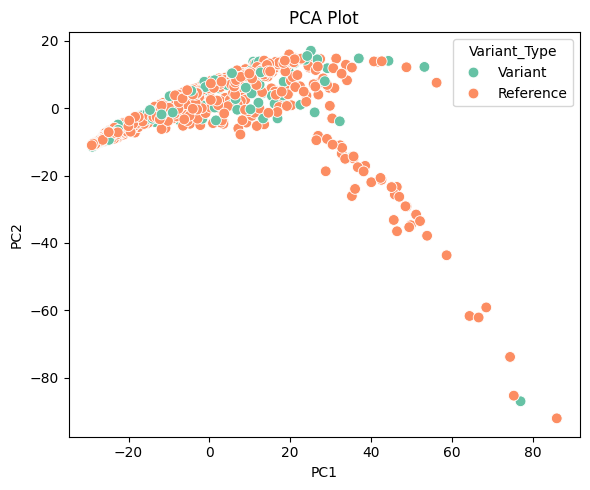

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# Perform UMAP
# Perform PCA
df = well_profiles_plate_agg.select(pl.col([col for col in well_profiles_plate_agg.columns if not col.startswith("Metadata_")]))

# Standardize the features before PCA
scaler = StandardScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

pca = PCA(n_components=10)
pca_result = pca.fit_transform(df)

pca_df = pd.DataFrame(pca_result, columns=[f"PC{i+1}" for i in range(pca_result.shape[1])])
pca_df["Metadata_gene_allele"] = well_profiles_plate_agg["Metadata_gene_allele"].to_numpy()
pca_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
pca_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_variant_type", palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("PCA Plot")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [11]:
# pca_df[(pca_df["PC1"]>20)&(pca_df["PC2"]<-10)]

In [30]:
# Get PCA loading scores
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=df.columns
)
pca_loadings.sort_values(by="PC1", ascending=False, inplace=True)
pca_loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Cells_Texture_DifferenceEntropy_GFP_5_03_256,0.048749,0.010999,0.001420,0.015509,-0.005608,0.020058,-0.003010,0.006234,0.000900,-0.012688
Cells_Texture_DifferenceEntropy_GFP_10_02_256,0.048736,0.011992,0.001433,0.015679,-0.004903,0.018663,-0.000870,0.004024,0.000376,-0.014189
Cells_Texture_DifferenceEntropy_GFP_10_00_256,0.048720,0.011961,0.001350,0.015800,-0.005052,0.018815,-0.000871,0.004021,0.000527,-0.014634
Cells_Texture_DifferenceEntropy_GFP_5_02_256,0.048712,0.010388,0.001740,0.015455,-0.006202,0.021246,-0.005542,0.008468,0.000804,-0.010714
Cells_Texture_DifferenceEntropy_GFP_10_03_256,0.048708,0.012634,0.001074,0.016399,-0.004351,0.017417,0.001067,0.002235,-0.000325,-0.014864
...,...,...,...,...,...,...,...,...,...,...
Nuclei_Texture_InfoMeas1_GFP_5_00_256,-0.047330,0.007157,0.000548,-0.019033,0.012741,-0.019926,-0.018055,0.004970,0.015637,-0.009669
Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,-0.047531,-0.010795,-0.021448,0.010236,0.001831,-0.010461,-0.014925,0.010707,0.027874,-0.013468
Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,-0.047539,-0.010484,-0.022134,0.009834,0.001591,-0.010484,-0.013957,0.010498,0.027378,-0.012068
Cytoplasm_Texture_InfoMeas1_GFP_20_01_256,-0.047596,-0.010859,-0.021841,0.008697,0.004700,-0.015903,-0.014021,0.002313,0.017629,-0.012261


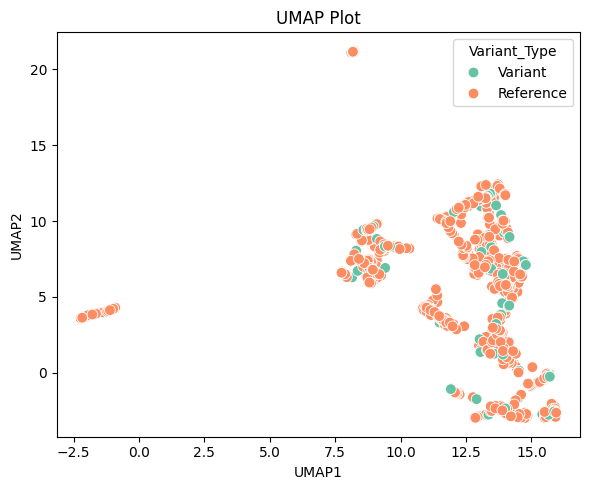

In [32]:
# from sklearn.preprocessing import StandardScaler

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
df = well_profiles_plate_agg.select(pl.col([col for col in well_profiles_plate_agg.columns if not col.startswith("Metadata_")]))

# Standardize the features before PCA
scaler = StandardScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

umap_result = umap_model.fit_transform(df.to_numpy())
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_gene_allele"] = well_profiles_plate_agg["Metadata_gene_allele"].to_numpy()
umap_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
umap_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_variant_type", palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [45]:
umap_df[umap_df["UMAP1"]<5]

,UMAP1,UMAP2,Metadata_gene_allele,Metadata_variant_type,Metadata_control_type
85,-5.408559,2.401598,BCL10,Variant,Allele
86,-5.443964,2.436691,BCL10_Leu8Leu,Reference,Allele
158,-4.339586,1.454342,DES,Variant,Allele
159,-4.822032,1.871822,DES_Ala135Val,Reference,Allele
160,-4.325285,1.440421,DES_Ala213Val,Reference,Allele
161,-4.478699,1.580750,DES_Ala237Thr,Reference,Allele
165,-5.196033,2.195946,DES_Ala397Thr,Reference,Allele
166,-4.363954,1.471305,DES_Arg127Pro,Reference,Allele
167,-4.976421,2.001152,DES_Arg150Gln,Reference,Allele
168,-4.243656,1.365429,DES_Arg16Cys,Reference,Allele


In [48]:
umap_df[(umap_df["UMAP1"]>5)&(umap_df["UMAP2"]>15)]

,UMAP1,UMAP2,Metadata_gene_allele,Metadata_variant_type,Metadata_control_type
267,10.670685,16.623707,GATA2_Cys373Arg,Reference,Allele
482,10.698064,16.720434,NMNAT1,Variant,Allele
483,10.612729,16.633656,NMNAT1_Arg207Trp,Reference,Allele
485,10.680852,16.699604,NMNAT1_Asn273Asp,Reference,Allele
487,10.589437,16.647108,NMNAT1_Leu153Val,Reference,Allele
488,10.634657,16.653881,NMNAT1_Ser255Asn,Reference,Allele
489,10.671806,16.605488,ORC6,Variant,Allele
490,10.619808,16.666800,ORC6_Tyr232Ser,Reference,Allele
552,10.573025,16.600382,PLA2G6,Variant,Allele
670,10.656266,16.667801,SNIP1,Variant,Allele


## Co-localization patterns

In [13]:
## Select colocalization metrics between meaningful channels
## Select columns that contain "Correlation" but not "Brightfield", brightfield doesn't provide useful information here
colocal_cols = [col for col in well_profiles.columns if "Correlation" in col and "Brightfield" not in col]
colocal_col_cat = set(["_".join(col.split('_')[1:3]) for col in colocal_cols])
print(colocal_col_cat)

colocal_col_dict = defaultdict(list)
for col in colocal_cols:
    colocal_col_dict["_".join(col.split('_')[1:3])].append(col)
# colocal_col_dict

{'Correlation_Overlap', 'Correlation_Manders', 'Correlation_RWC', 'Texture_Correlation', 'Correlation_K', 'Correlation_Costes', 'Correlation_Correlation'}


## WT gene well profiles

In [14]:
well_profiles_wt = well_profiles.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)
well_profiles_wt

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_19_B7A…","""B08""","""ACACB""",0.209386,-0.102414,-0.100254,-0.10583,0.218471,0.55103,0.872907,0.009793,0.000829,0.078723,0.916885,1.0,1.0,0.51685,1.0,0.567537,1.0,1.0,0.135624,0.09144,0.092116,0.091375,0.690829,6.608265,10.687915,10.700838,10.70103,1.233437,17.793319,0.048558,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2024_01_22_B7A…","""B08""","""ACACB""",0.20117,-0.09214,-0.086157,-0.080617,0.185177,0.527714,0.873305,0.0,0.0,0.0,0.958477,1.0,0.0,0.0,0.0,0.665684,1.0,0.998969,0.363056,0.105012,0.104847,0.104458,0.763093,2.307217,9.258984,9.228502,9.441518,1.229213,21.36025,0.040013,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

### Co-localization patterns

                                                mean       std  Corr_cat
index                                                                   
Nuclei_Correlation_Correlation_GFP_Mito     0.395787  0.212546  GFP_Mito
Cytoplasm_Correlation_Correlation_GFP_Mito  0.612596  0.194620  GFP_Mito
Cells_Correlation_Correlation_GFP_Mito      0.560901  0.180248  GFP_Mito
Nuclei_Correlation_Correlation_DNA_GFP     -0.131063  0.451859   DNA_GFP
Cytoplasm_Correlation_Correlation_DNA_GFP   0.283727  0.159057   DNA_GFP
Cells_Correlation_Correlation_DNA_GFP       0.197164  0.355795   DNA_GFP
Nuclei_Correlation_Correlation_AGP_GFP      0.199590  0.259077   AGP_GFP
Cytoplasm_Correlation_Correlation_AGP_GFP   0.219036  0.120225   AGP_GFP
Cells_Correlation_Correlation_AGP_GFP       0.192089  0.129070   AGP_GFP


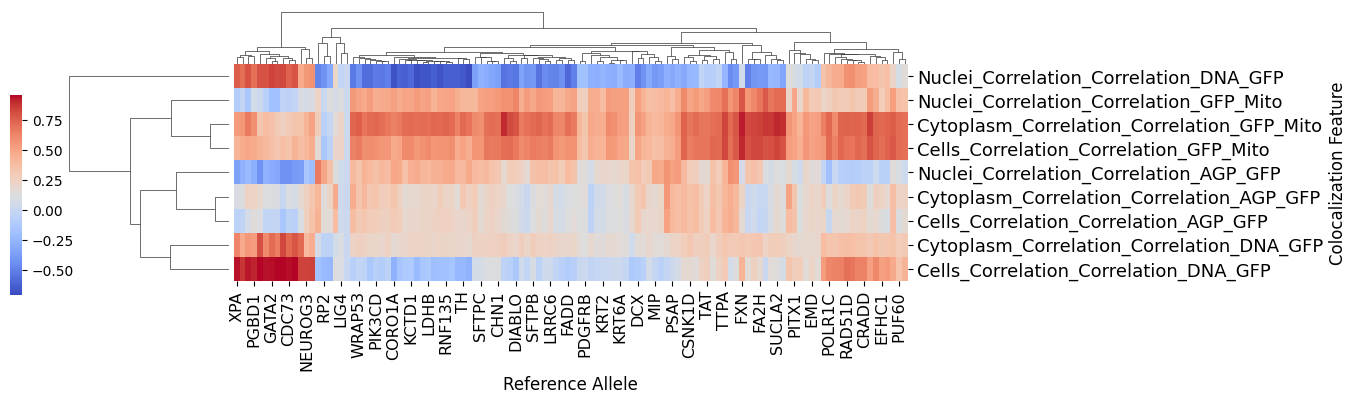

In [41]:
well_profiles_wt_gene = well_profiles_wt.group_by("Metadata_gene_allele").agg(
    pl.col(col).median().alias(col)
    for col in colocal_cols
).select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

## Calculate mean and standard deviation for each column
column_stats = well_profiles_wt_gene[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T.reset_index()
column_stats["Corr_cat"] = column_stats["index"].apply(lambda x: "_".join(x.split("_")[-2:]))
## Sort columns by the sum of mean and std in descending order
sorted_columns = column_stats.sort_values(by=["Corr_cat","index"], ascending=False)
sorted_columns.set_index("index", inplace=True)
print(sorted_columns)

# sorted_columns.loc[colocal_col_dict["Correlation_Correlation"]]
# sorted_columns.loc[colocal_col_dict["Correlation_Costes"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_RWC"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_Manders"]] ## means nearly all to 1, meaningless here

# ## filter out corr columns with mean <= 1
# sorted_columns = sorted_columns[sorted_columns["mean"] > 1]
# display(sorted_columns)

g = sns.clustermap(well_profiles_wt_gene[sorted_columns.index].T, figsize=(12, 4), cmap="coolwarm", 
cbar_pos=(-.03, .25, .01, .5), #xticklabels=2, 
row_cluster=True, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=11.5)
rot_xticks = plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="left", fontsize=13)
rot_xticks = g.ax_heatmap.set_xlabel("Reference Allele", fontsize=12)
rot_xticks = g.ax_heatmap.set_ylabel("Colocalization Feature", fontsize=12)
# g.fig.suptitle("Mislocalized Variants' Reference Alleles: Pearson's Correlation between Channels", y=1.) 

## Well Profiles Visualization

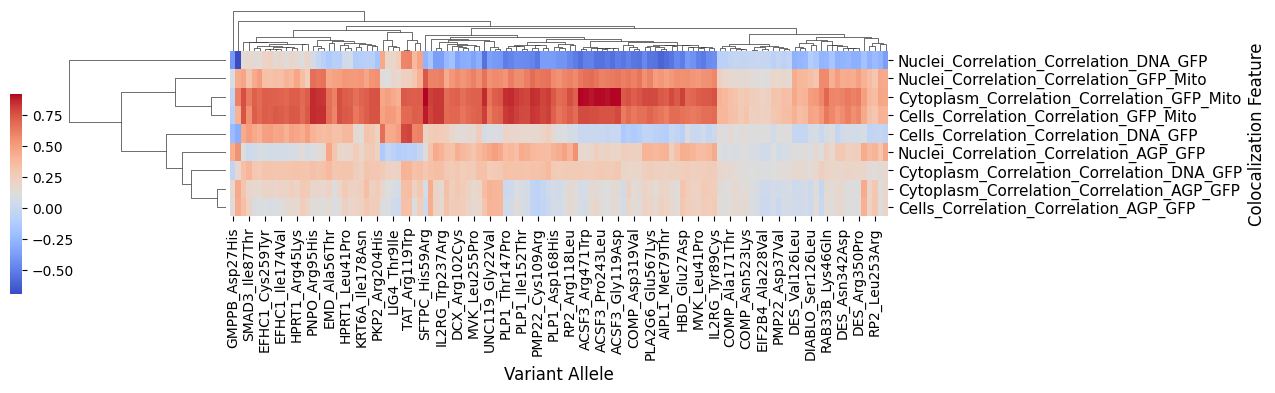

In [43]:
well_profiles_var = well_profiles.filter(
    pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)

well_profiles_var_allele = well_profiles_var.group_by(["Metadata_gene_allele"]).agg(
    pl.col(col).median().alias(col)
        for col in colocal_cols
).unique().select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

# Calculate mean and standard deviation for each column
column_stats = well_profiles_var_allele[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T
# Sort columns by the sum of mean and std in descending order
# sorted_columns = column_stats.sort_values(by=["mean", "std"], ascending=False)

# display(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index])

# sns.set(font_scale=.8)
g = sns.clustermap(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index].T, figsize=(12, 4), cmap="coolwarm", 
cbar_pos=(-.03, .25, .01, .5), #xticklabels=2, 
row_cluster=True, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=10)
rot_xticks = plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="left", fontsize=11)
rot_xticks = g.ax_heatmap.set_xlabel("Variant Allele", fontsize=12)
rot_xticks = g.ax_heatmap.set_ylabel("Colocalization Feature", fontsize=12)


# gfp_cols = [col for col in well_profiles_merge_plate.columns if "GFP" in col]
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in gfp_cols if well_profiles_merge_plate[col].std() > 2] + ["Metadata_gene_allele"]
# )

In [49]:
# display(well_profiles_var_allele[sorted_columns.index])
# display(well_profiles_wt_gene[sorted_columns.index])

well_profiles_var_allele_regroup = well_profiles_var_allele.loc[sig_misloc_alleles,].reset_index()
well_profiles_var_allele_regroup["Gene"] = well_profiles_var_allele_regroup["Metadata_gene_allele"].apply(lambda x: x.split("_")[0])

misloc_scores = pd.DataFrame()
for gene, group in well_profiles_var_allele_regroup.groupby("Gene"):
    # print(gene)
    # display(group)
    group = group.set_index("Metadata_gene_allele")
    group = group - well_profiles_wt_gene.loc[gene]
    misloc_scores = pd.concat([misloc_scores, group], axis=0)

# misloc_scores.columns = [col+"_var-wt" for col in misloc_scores.columns]
misloc_scores

,Cells_Correlation_Correlation_AGP_GFP,Cells_Correlation_Correlation_DNA_GFP,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Costes_AGP_GFP,Cells_Correlation_Costes_DNA_GFP,Cells_Correlation_Costes_GFP_AGP,Cells_Correlation_Costes_GFP_DNA,Cells_Correlation_Costes_GFP_Mito,Cells_Correlation_Costes_Mito_GFP,Cells_Correlation_K_AGP_GFP,...,Nuclei_Texture_Correlation_GFP_10_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Nuclei_Texture_Correlation_GFP_20_00_256,Nuclei_Texture_Correlation_GFP_20_01_256,Nuclei_Texture_Correlation_GFP_20_02_256,Nuclei_Texture_Correlation_GFP_20_03_256,Nuclei_Texture_Correlation_GFP_5_00_256,Nuclei_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Correlation_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_5_03_256
Metadata_gene_allele,,,,,,,,,,,,,,,,,,,,,
ACSF3_Thr358Ile,-0.198333,-0.339428,0.233743,-0.007262,-0.006532,0.000000,0.355117,0.000000,0.000101,-0.081000,...,-0.517312,-0.504952,0.000000,0.000000,0.000000,0.000000,-0.420288,-0.473053,-0.431365,-0.493689
ACSF3_Ser431Tyr,-0.301760,0.099223,-0.024178,-0.224049,-0.035734,-0.030480,-0.171261,0.000000,0.000031,-0.205888,...,0.451776,0.479928,1.000000,1.000000,1.000000,1.000000,0.364448,0.422510,0.372056,0.420498
ACSF3_Asp457Asn,-0.321329,-0.348617,0.241134,-0.005197,-0.003620,0.000000,0.064869,-0.000177,-0.000763,-0.082921,...,-0.547559,-0.521004,0.000000,0.000000,0.000000,0.000000,-0.495091,-0.520600,-0.515182,-0.541976
ACSF3_Pro243Leu,-0.269969,-0.346456,0.217324,-0.011654,-0.005864,0.000000,0.033845,0.000000,0.000066,-0.102865,...,-0.517450,-0.519294,0.000000,0.000000,0.000000,0.000000,-0.387990,-0.493091,-0.416555,-0.451129
ACSF3_Met266Val,-0.232930,-0.348781,0.216314,-0.014912,-0.005074,0.000000,-0.010911,0.000000,0.000150,-0.139852,...,-0.502904,-0.490095,0.000000,0.000000,0.000000,0.000000,-0.400544,-0.472104,-0.419861,-0.448663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TH_Glu250Gln,-0.038152,0.341609,-0.185059,-0.344773,-0.199593,-0.156528,-0.706247,0.000000,-0.000043,-1.546976,...,0.926591,1.011336,1.046677,1.103011,1.023487,1.097005,0.697200,0.839464,0.711625,0.840803
TTPA_Gly246Arg,-0.008710,-0.053392,-0.040964,0.000000,0.000319,0.000000,0.061269,0.000104,0.000000,-2.499226,...,-0.020095,-0.004407,0.025901,0.094588,0.016992,0.061874,-0.086938,-0.042438,-0.080490,-0.064098
UNC119_Gly22Val,0.025281,-0.391414,-0.162012,0.000000,-0.000209,0.000000,-0.246847,-0.002621,-0.000193,1.069590,...,-0.066738,-0.087976,-0.032702,-0.096823,-0.022201,-0.117062,-0.046942,-0.082244,0.033964,0.023552


In [92]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import numpy as np

silhouette_scores = []
cluster_range = range(2, 10)  # Trying clusters from 2 to 9
df = misloc_scores[sorted_columns.index] #.dropna(axis=1).copy()

for k in cluster_range:
    clustering = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = clustering.fit_predict(df)
    score = silhouette_score(df, labels)
    silhouette_scores.append(score)
    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Select the number of clusters that has the highest silhouette score
optimal_clusters = cluster_range[np.argmax(silhouette_scores)]
print(f"Optimal number of clusters determined: {optimal_clusters}")

Clusters: 2, Silhouette Score: 0.4779
Clusters: 3, Silhouette Score: 0.3462
Clusters: 4, Silhouette Score: 0.3582
Clusters: 5, Silhouette Score: 0.3363
Clusters: 6, Silhouette Score: 0.3184
Clusters: 7, Silhouette Score: 0.2946
Clusters: 8, Silhouette Score: 0.3336
Clusters: 9, Silhouette Score: 0.3497
Optimal number of clusters determined: 2


In [93]:
# ----------------------------
# 3. Perform Hierarchical Clustering with the Optimal Cluster Count
# ----------------------------
agg_model = AgglomerativeClustering(n_clusters=4, linkage='ward')
df.loc[:,'cluster'] = agg_model.fit_predict(df)

/tmp/ipykernel_326136/3202266153.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:,'cluster'] = agg_model.fit_predict(df)


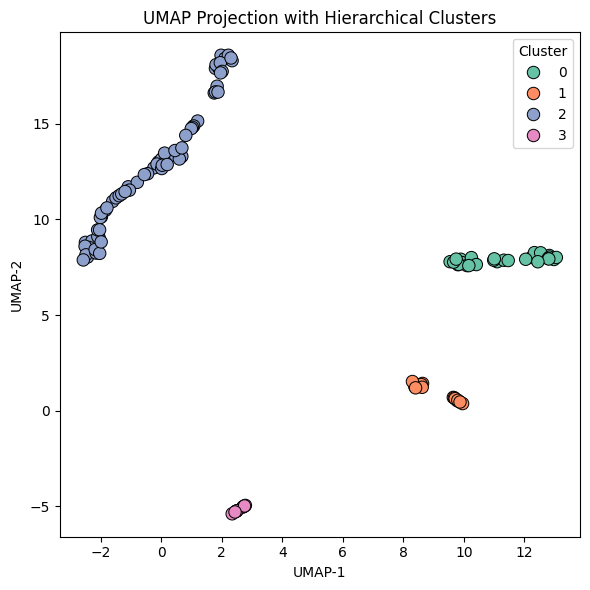

In [114]:
# ----------------------------
# 4. Compute UMAP Projection and Plot the Clusters
# ----------------------------
umap_reducer = umap.UMAP(random_state=42)
embedding = umap_reducer.fit_transform(df)
df.loc[:,'UMAP-1'] = embedding[:, 0]
df.loc[:,'UMAP-2'] = embedding[:, 1]

plt.figure(figsize=(6, 6))
sns.scatterplot(x='UMAP-1', y='UMAP-2', hue='cluster', 
                palette='Set2', data=df, s=80, edgecolor='k')
plt.title("UMAP Projection with Hierarchical Clusters")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

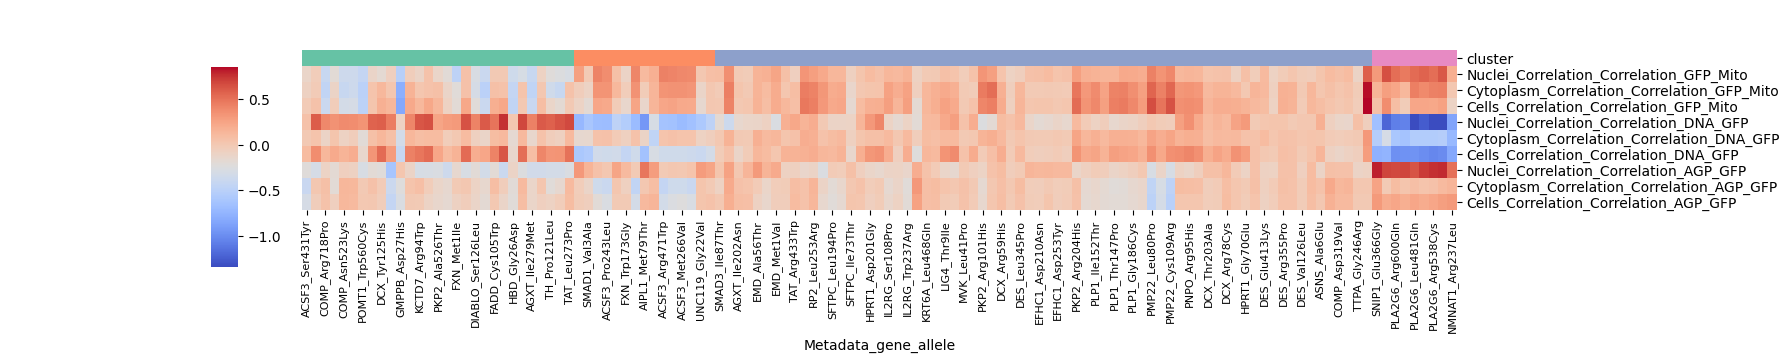

In [113]:
# df = df.set_index("Group2")
unique_clusters = np.sort(df['cluster'].unique())
palette = sns.color_palette("Set2", len(unique_clusters))
lut = dict(zip(unique_clusters, palette))
row_colors = df['cluster'].map(lut)

# Create the clustermap. We use only the original features.
# The row_colors argument is used to annotate the rows based on our clusters.
g = sns.clustermap(df.sort_values(by="cluster")[sorted_columns.index].T,
                   col_colors=row_colors,
                   metric="euclidean",
                   method="ward",
                   cmap="coolwarm",
                   cbar_pos=(.12, .32, .015, .5),
                   figsize=(18, 4),
                   row_cluster=False,
                   colors_ratio=0.08,
                   col_cluster=False)
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=8)

# Optionally, add a legend for the row_colors
# for label in unique_clusters:
#     g.ax_row_dendrogram.bar(1, 0, color=lut[label],
#                             label=f'Cluster {label}', linewidth=0)
# g.ax_row_dendrogram.legend(loc="upper right", ncol=1, title="Cluster Labels")
# plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=6)
# plt.setp(g.ax_heatmap.set_ylabel(""), rotation=0, fontsize=6)
# plt.suptitle("Seaborn Clustermap with Assigned Clusters", y=1.05)
# plt.show()

In [ ]:
g = sns.clustermap(misloc_scores.loc[sig_misloc_alleles,sorted_columns.index].T, figsize=(12, 4), cmap="coolwarm", 
cbar_pos=(-.03, .25, .01, .5), #xticklabels=2, 
row_cluster=True, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=10)
rot_xticks = plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="left", fontsize=11)
rot_xticks = g.ax_heatmap.set_xlabel("Variant Allele", fontsize=12)
rot_xticks = g.ax_heatmap.set_ylabel("Colocalization Feature", fontsize=12)

In [59]:
[idx for idx in misloc_scores.index if "PLA2G6" in idx]

['PLA2G6_Glu567Lys',
 'PLA2G6_Arg600Gln',
 'PLA2G6_Leu481Gln',
 'PLA2G6_Val310Glu',
 'PLA2G6_Thr585Ile',
 'PLA2G6_Arg538Cys']

In [ ]:
# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(misloc_scores.loc[sig_misloc_alleles, sorted_columns.index])
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_gene_allele"] = sig_misloc_alleles

/tmp/ipykernel_151077/643913833.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], palette="Set2", s=60, ax=ax) ## hue=variant_type,
/tmp/ipykernel_151077/643913833.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Variant_Type")


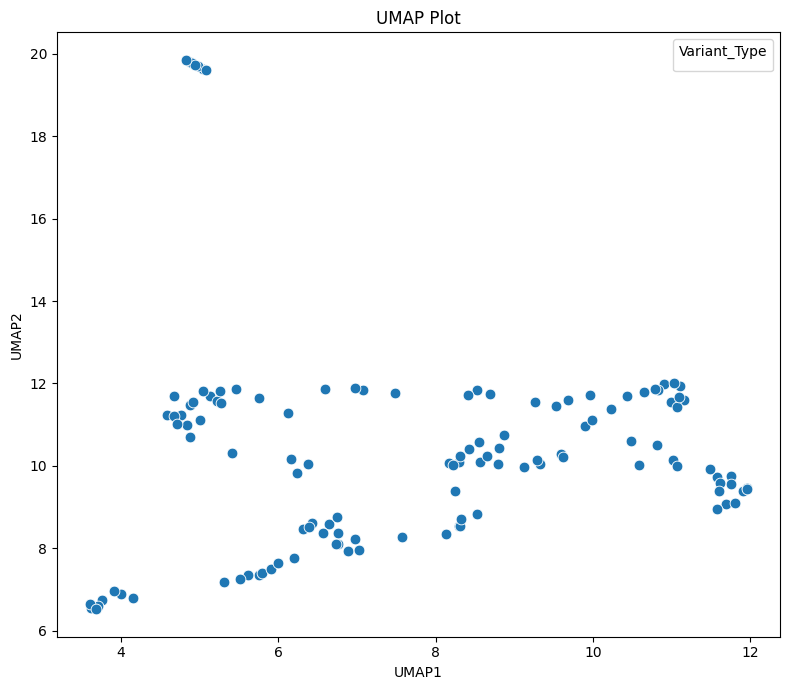

In [62]:
# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(8, 7))
sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [20]:
local_wtvar.filter(pl.col("allele_0").str.contains("ACSF3")).sort(pl.col("allele_0","Batch"))#.select(pl.col("allele_0")).unique()

Classifier_type,allele_0,Allele_set,Batch,AUROC_thresh,AUROC_mean,trainsize_0_mean,testsize_0_mean,trainsize_1_mean,testsize_1_mean,Training_imbalance_mean,mislocalized
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,i32
"""localization""","""ACSF3_Ala197Th…","""A1P1""","""B7""",0.71418,0.967056,497.25,165.75,806.25,268.75,1.624526,1
"""localization""","""ACSF3_Arg10Trp…","""A1P1""","""B7""",0.71418,0.953108,1461.0,487.0,806.25,268.75,1.812773,1
"""localization""","""ACSF3_Arg471Tr…","""A1P1""","""B7""",0.71418,0.975904,807.0,269.0,806.25,268.75,1.043461,1
"""localization""","""ACSF3_Arg471Tr…","""A1P1""","""B8""",0.861392,0.95188,276.75,92.25,137.25,45.75,2.026597,1
"""localization""","""ACSF3_Arg558Tr…","""A1P1""","""B7""",0.71418,0.972141,483.75,161.25,806.25,268.75,1.679772,1
"""localization""","""ACSF3_Arg558Tr…","""A1P1""","""B8""",0.861392,0.959306,144.75,48.25,137.25,45.75,1.157665,1
"""localization""","""ACSF3_Asp457As…","""A1P1""","""B7""",0.71418,0.975797,432.75,144.25,806.25,268.75,1.863958,1
"""localization""","""ACSF3_Asp457As…","""A1P1""","""B8""",0.861392,0.957957,203.25,67.75,137.25,45.75,1.487355,1
"""localization""","""ACSF3_Glu359Ly…","""A1P1""","""B7""",0.71418,0.975252,933.0,311.0,806.25,268.75,1.157019,1


In [64]:
umap_df[umap_df["UMAP2"]>18]["Metadata_gene_allele"].to_list()

['ACSF3_Arg471Trp',
 'ACSF3_Arg558Trp',
 'ACSF3_Asp457Asn',
 'ACSF3_Thr358Ile',
 'ACSF3_Met266Val',
 'ACSF3_Gly119Asp',
 'ACSF3_Pro243Leu']

In [ ]:
inputs_dir = "../../../../3_integrated_assay_results/1_inputs"
ai_scores = pl.read_csv(f"{inputs_dir}/ai_pred_struc_scores.tsv", separator="\t", infer_schema_length=10000)

ai_acsf3 = ai_scores.filter(pl.col("symbol")=="ACSF3").with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("variant")
).filter(pl.col("symbol")=="ACSF3")

ai_acsf3.with_columns(
    pl.when(pl.col("variant").is_in(['ACSF3_Arg471Trp',
        'ACSF3_Arg558Trp',
        'ACSF3_Asp457Asn',
        'ACSF3_Thr358Ile',
        'ACSF3_Met266Val',
        'ACSF3_Gly119Asp',
        'ACSF3_Pro243Leu']))
    .then(pl.lit("1_Mislocalized"))
    .otherwise(pl.lit("2_Non-Mislocalized"))
    .alias("Misloc")
)

In [ ]:
local_wtvar.filter(pl.col("allele_0").str.contains("PLA2G6")).sort(pl.col("AUROC_mean"))
# [al for al in all_alleles if "PLA2G6" in al]

Classifier_type,allele_0,Allele_set,Batch,AUROC_thresh,AUROC_mean,trainsize_0_mean,testsize_0_mean,trainsize_1_mean,testsize_1_mean,Training_imbalance_mean,mislocalized
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,i32
"""localization""","""PLA2G6_Leu481G…","""A1P3""","""B8""",0.861392,0.975955,80.666667,40.333333,100.666667,50.333333,1.26084,1
"""localization""","""PLA2G6_Thr585I…","""A1P3""","""B8""",0.861392,0.980062,122.0,61.0,100.666667,50.333333,1.202233,1
"""localization""","""PLA2G6_Arg600G…","""A1P3""","""B8""",0.861392,0.983921,146.666667,73.333333,100.666667,50.333333,1.457242,1
"""localization""","""PLA2G6_Glu567L…","""A1P3""","""B8""",0.861392,0.988764,72.0,36.0,100.666667,50.333333,1.40098,1
"""localization""","""PLA2G6_Arg538C…","""A1P3""","""B7""",0.71418,0.991076,628.5,209.5,341.25,113.75,1.886324,1
"""localization""","""PLA2G6_Val310G…","""A1P3""","""B7""",0.71418,0.993679,462.75,154.25,341.25,113.75,1.457059,1
"""localization""","""PLA2G6_Leu481G…","""A1P3""","""B7""",0.71418,0.99416,408.75,136.25,341.25,113.75,1.29248,1
"""localization""","""PLA2G6_Glu567L…","""A1P3""","""B7""",0.71418,0.994567,295.5,98.5,341.25,113.75,1.159498,1
"""localization""","""PLA2G6_Arg600G…","""A1P3""","""B7""",0.71418,0.994797,486.75,162.25,341.25,113.75,1.440416,1


In [65]:
umap_df[umap_df["UMAP1"]<4.5]["Metadata_gene_allele"].to_list()

['PLA2G6_Glu567Lys',
 'PLA2G6_Arg600Gln',
 'PLA2G6_Leu481Gln',
 'SNIP1_Glu366Gly',
 'PLA2G6_Val310Glu',
 'XPA_Cys108Phe',
 'NMNAT1_Arg237Leu',
 'PLA2G6_Thr585Ile',
 'PLA2G6_Arg538Cys']

In [53]:
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in well_profiles_merge_plate.columns if not col.startswith("Metadata_")] + ["Metadata_gene_allele"]
# ).to_pandas().set_index("Metadata_gene_allele").loc[misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"],:]

# # from sklearn.preprocessing import StandardScaler
# # scaler = StandardScaler()
# # well_profiles_scaled = pd.DataFrame(scaler.fit_transform(well_profiles_merge_plate), columns=well_profiles_merge_plate.columns, index=well_profiles_merge_plate.index)
# # display(well_profiles_scaled)

# sns.clustermap(well_profiles_scaled, figsize=(20, 40), standard_scale=0, cmap="coolwarm", row_cluster=True, col_cluster=True) ## , "viridis"
# plt.show()